# Análise dos tempos de ordenação: gráficos

Gráficos feitos com matplotlib a partir dos CSVs de `dados/`, gerados por `src/experimento.py`.

Para ver tudo: **Executar tudo** (ou `Kernel > Restart & Run All`). O notebook não grava nenhum arquivo.

Os três algoritmos são: **QR** (Quick Sort Recursivo), **QI** (Quick Sort Iterativo) e **ME** (Merge Sort).

## 0. Preparação

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

RAIZ = Path.cwd()
if not (RAIZ / "dados").exists():
    RAIZ = RAIZ.parent
DADOS = RAIZ / "dados"

FORMATOS = ["QR-QI-ME", "QR-ME-QI", "QI-QR-ME", "QI-ME-QR", "ME-QR-QI", "ME-QI-QR"]
ALGORITMOS = ["Quick Sort Recursivo", "Quick Sort Iterativo", "Merge Sort"]
SIGLA = {"Quick Sort Recursivo": "QR", "Quick Sort Iterativo": "QI", "Merge Sort": "ME"}
CORES = {"Quick Sort Recursivo": "#4C78A8", "Quick Sort Iterativo": "#F58518",
         "Merge Sort": "#54A24B"}
CONFIANCA = 0.95

arquivos = [DADOS / "formato_{}.csv".format(f) for f in FORMATOS]
faltando = [a.name for a in arquivos if not a.exists()]
if faltando:
    raise FileNotFoundError("Arquivos nao encontrados: " + ", ".join(faltando))

df = pd.concat([pd.read_csv(a) for a in arquivos], ignore_index=True)
validas = df[df["descartada"] == "nao"].copy()


def resumo(x):
    x = np.asarray(x, dtype=float)
    n = len(x)
    media = x.mean()
    desvio = x.std(ddof=1)
    t = stats.t.ppf((1 + CONFIANCA) / 2, n - 1)
    margem = t * desvio / np.sqrt(n)
    return {"n": n, "media": media, "desvio": desvio, "margem": margem,
            "ic_inf": media - margem, "ic_sup": media + margem,
            "erro_relativo": margem / media}


def tabela(linhas, rotulos):
    return pd.DataFrame([
        {"": rotulo, "n": x["n"], "media (ms)": x["media"], "desvio (ms)": x["desvio"],
         "IC 95% inf (ms)": x["ic_inf"], "IC 95% sup (ms)": x["ic_sup"],
         "erro relativo": x["erro_relativo"]}
        for rotulo, x in zip(rotulos, linhas)
    ]).round(4)


from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def legenda_distribuicao(ax):
    ax.legend(handles=[
        Line2D([], [], marker="o", linestyle="", color="gray", markersize=5,
               label="ponto = uma rodada"),
        Patch(facecolor="lightgray", edgecolor="black", alpha=0.6,
              label="caixa = 1º ao 3º quartil"),
        Line2D([], [], color="black", label="linha na caixa = mediana"),
    ], loc="best", fontsize=8)


def legenda_media(ax):
    ax.legend(handles=[
        Line2D([], [], marker="o", linestyle="", color="gray", markersize=8,
               label="ponto = média"),
        Line2D([], [], color="gray", linewidth=2, label="barra = IC de 95%"),
    ], loc="best", fontsize=8)


print("Arquivos lidos:", len(arquivos))
print("Rodadas validas no total:", len(validas))

Arquivos lidos: 6
Rodadas validas no total: 852


### Funções de gráfico

In [2]:
def grafico_algoritmo(nome):
    sub = validas[validas["algoritmo"] == nome]
    dados = [sub.loc[sub["formato"] == f, "tempo_ms"].values for f in FORMATOS]
    resumos = [resumo(d) for d in dados]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    caixas = ax1.boxplot(dados, patch_artist=True, showfliers=False, widths=0.5)
    for caixa in caixas["boxes"]:
        caixa.set_facecolor(CORES[nome])
        caixa.set_alpha(0.25)
    rng = np.random.default_rng(42)
    for i, d in enumerate(dados, 1):
        ax1.scatter(rng.normal(i, 0.07, len(d)), d, s=12, color=CORES[nome],
                    alpha=0.6, edgecolors="none")
    ax1.set_xticks(range(1, len(FORMATOS) + 1))
    ax1.set_xticklabels(FORMATOS)
    ax1.set_title("Distribuicao dos tempos por formato")
    ax1.set_ylabel("Tempo de ordenacao (ms)")
    ax1.grid(axis="y", alpha=0.3)
    legenda_distribuicao(ax1)

    medias = [r["media"] for r in resumos]
    margens = [r["margem"] for r in resumos]
    ax2.errorbar(range(1, len(FORMATOS) + 1), medias, yerr=margens, fmt="o",
                 color=CORES[nome], ecolor="gray", capsize=6, markersize=8)
    ax2.set_xticks(range(1, len(FORMATOS) + 1))
    ax2.set_xticklabels(FORMATOS)
    ax2.set_title("Media e IC de 95% por formato")
    ax2.set_ylabel("Tempo medio (ms)")
    ax2.grid(True, linestyle="--", alpha=0.4)
    legenda_media(ax2)

    fig.suptitle(nome, fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()

    display(tabela(resumos, FORMATOS))

In [3]:
def grafico_formato(formato):
    sub = df[df["formato"] == formato]
    val = sub[sub["descartada"] == "nao"]
    dados = [val.loc[val["algoritmo"] == a, "tempo_ms"].values for a in ALGORITMOS]
    resumos = [resumo(d) for d in dados]
    siglas = [SIGLA[a] for a in ALGORITMOS]

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

    caixas = ax1.boxplot(dados, patch_artist=True, showfliers=False, widths=0.5)
    for caixa, a in zip(caixas["boxes"], ALGORITMOS):
        caixa.set_facecolor(CORES[a])
        caixa.set_alpha(0.25)
    rng = np.random.default_rng(42)
    for i, (a, d) in enumerate(zip(ALGORITMOS, dados), 1):
        ax1.scatter(rng.normal(i, 0.07, len(d)), d, s=12, color=CORES[a],
                    alpha=0.6, edgecolors="none")
    ax1.set_xticks([1, 2, 3])
    ax1.set_xticklabels(siglas)
    ax1.set_title("Distribuicao dos tempos")
    ax1.set_ylabel("Tempo de ordenacao (ms)")
    ax1.grid(axis="y", alpha=0.3)
    legenda_distribuicao(ax1)

    for i, (a, r) in enumerate(zip(ALGORITMOS, resumos), 1):
        ax2.errorbar(i, r["media"], yerr=r["margem"], fmt="o", color=CORES[a],
                     ecolor=CORES[a], capsize=8, markersize=9)
    ax2.set_xticks([1, 2, 3])
    ax2.set_xticklabels(siglas)
    ax2.set_xlim(0.5, 3.5)
    ax2.set_title("Media e IC de 95%")
    ax2.set_ylabel("Tempo medio (ms)")
    ax2.grid(True, linestyle="--", alpha=0.4)
    legenda_media(ax2)

    inicio = df.loc[df["fase"] == "aquecimento", "rodada"].min()
    fim = df.loc[df["fase"] == "aquecimento", "rodada"].max()
    ax3.axvspan(inicio - 0.5, fim + 0.5, color="gray", alpha=0.15, label="aquecimento")
    for a in ALGORITMOS:
        s = sub[sub["algoritmo"] == a].sort_values("rodada")
        ax3.plot(s["rodada"], s["tempo_ms"], color=CORES[a], linewidth=1, alpha=0.8,
                 label=SIGLA[a])
    ax3.set_title("Tempos ao longo das rodadas")
    ax3.set_xlabel("Rodada")
    ax3.set_ylabel("Tempo de ordenacao (ms)")
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    fig.suptitle("Formato " + " > ".join(siglas), fontsize=14, fontweight="bold")
    fig.tight_layout()
    plt.show()

    display(tabela(resumos, ALGORITMOS))

## 1. Gráficos por algoritmo

Cada gráfico mostra um algoritmo nos seis formatos de rodízio.

- **Esquerda:** distribuição dos tempos. A caixa vai do 1º ao 3º quartil, a linha é a mediana e cada ponto é uma rodada.
- **Direita:** média com o IC de 95%, em cada formato.

### 1.1 Quick Sort Recursivo

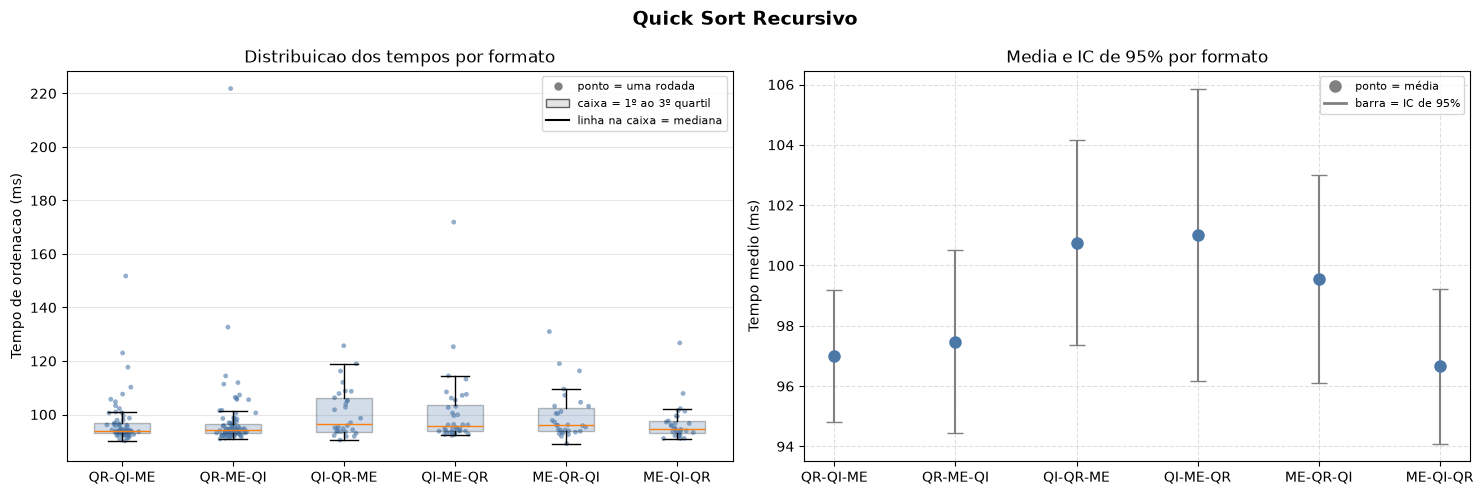

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,QR-QI-ME,67,96.9987,8.9899,94.8059,99.1915,0.0226
1,QR-ME-QI,91,97.4747,14.5135,94.4521,100.4973,0.0310
2,QI-QR-ME,30,100.7584,9.1082,97.3573,104.1594,0.0338
3,QI-ME-QR,36,101.0113,14.3509,96.1557,105.8670,0.0481
4,ME-QR-QI,30,99.5615,9.2210,96.1183,103.0047,0.0346
5,ME-QI-QR,30,96.6606,6.8791,94.0919,99.2293,0.0266


In [4]:
grafico_algoritmo("Quick Sort Recursivo")

### 1.2 Quick Sort Iterativo

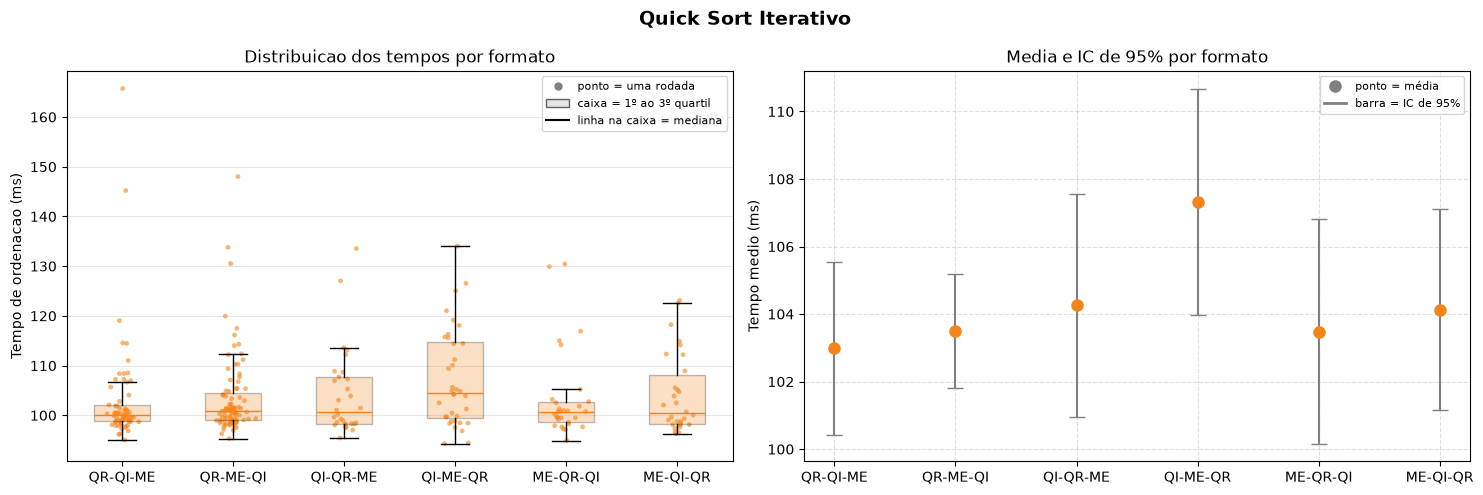

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,QR-QI-ME,67,102.9933,10.4991,100.4324,105.5542,0.0249
1,QR-ME-QI,91,103.4915,8.1297,101.7984,105.1846,0.0164
2,QI-QR-ME,30,104.2560,8.8156,100.9642,107.5478,0.0316
3,QI-ME-QR,36,107.3243,9.9136,103.9701,110.6786,0.0313
4,ME-QR-QI,30,103.4819,8.8879,100.1631,106.8007,0.0321
5,ME-QI-QR,30,104.1315,7.9688,101.1559,107.1071,0.0286


In [5]:
grafico_algoritmo("Quick Sort Iterativo")

### 1.3 Merge Sort

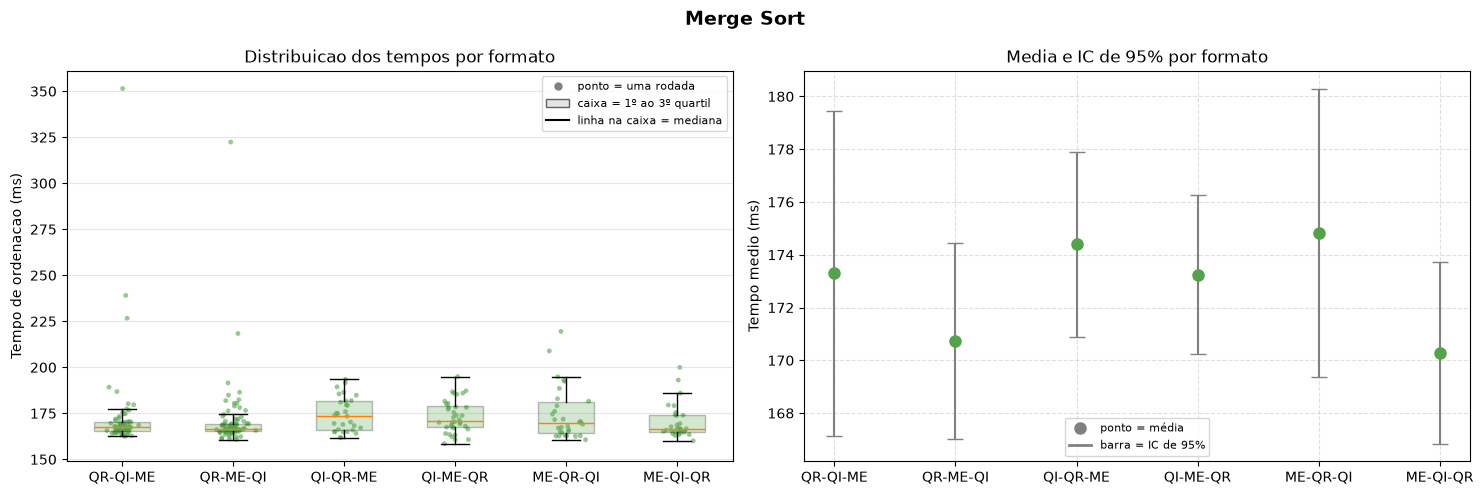

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,QR-QI-ME,67,173.3004,25.2551,167.1403,179.4606,0.0355
1,QR-ME-QI,91,170.7395,17.8522,167.0216,174.4574,0.0218
2,QI-QR-ME,30,174.3945,9.3750,170.8938,177.8951,0.0201
3,QI-ME-QR,36,173.2428,8.8937,170.2336,176.2520,0.0174
4,ME-QR-QI,30,174.8284,14.6487,169.3585,180.2983,0.0313
5,ME-QI-QR,30,170.2872,9.2215,166.8439,173.7306,0.0202


In [6]:
grafico_algoritmo("Merge Sort")

## 2. Gráficos por formato de rodízio

Cada gráfico mostra os três algoritmos em um formato. Os painéis são:

- **Esquerda:** distribuição dos tempos de cada algoritmo, com um ponto por rodada.
- **Centro:** média com o IC de 95%.
- **Direita:** tempo de cada rodada, na ordem em que foi executada. A faixa cinza é o aquecimento, que não entra na análise.

### 2.1 Formato QR > QI > ME

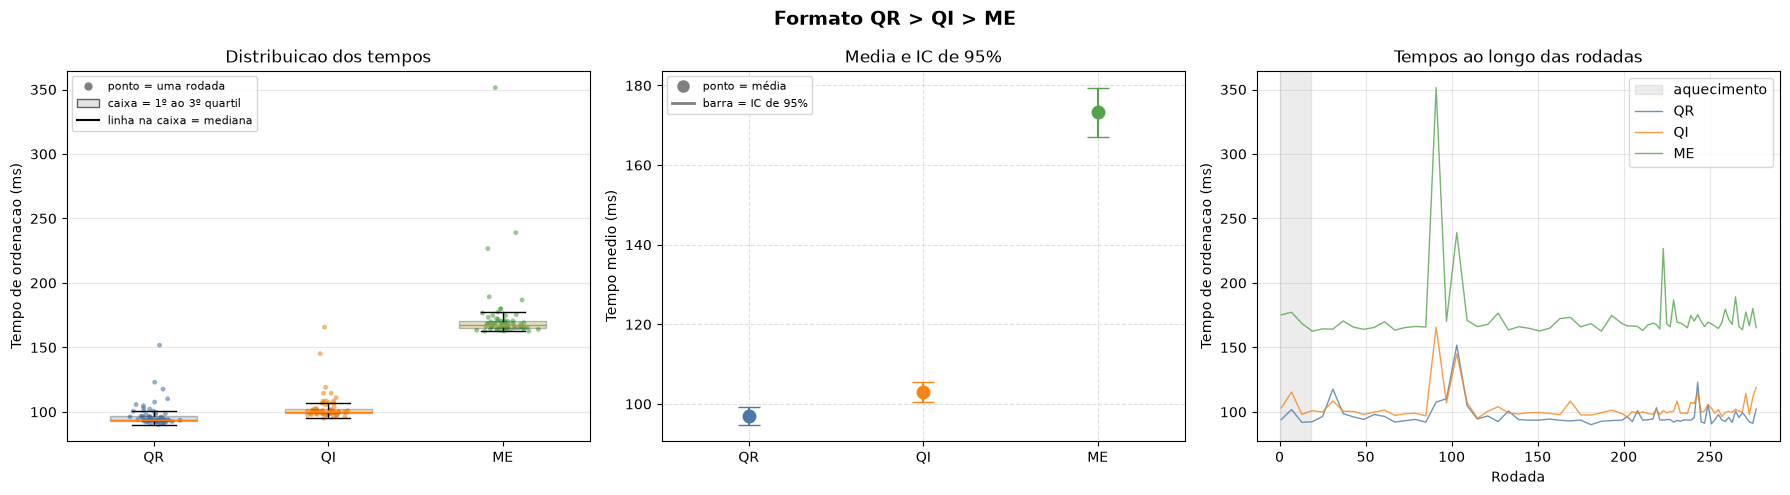

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,67,96.9987,8.9899,94.8059,99.1915,0.0226
1,Quick Sort Iterativo,67,102.9933,10.4991,100.4324,105.5542,0.0249
2,Merge Sort,67,173.3004,25.2551,167.1403,179.4606,0.0355


In [7]:
grafico_formato("QR-QI-ME")

### 2.2 Formato QR > ME > QI

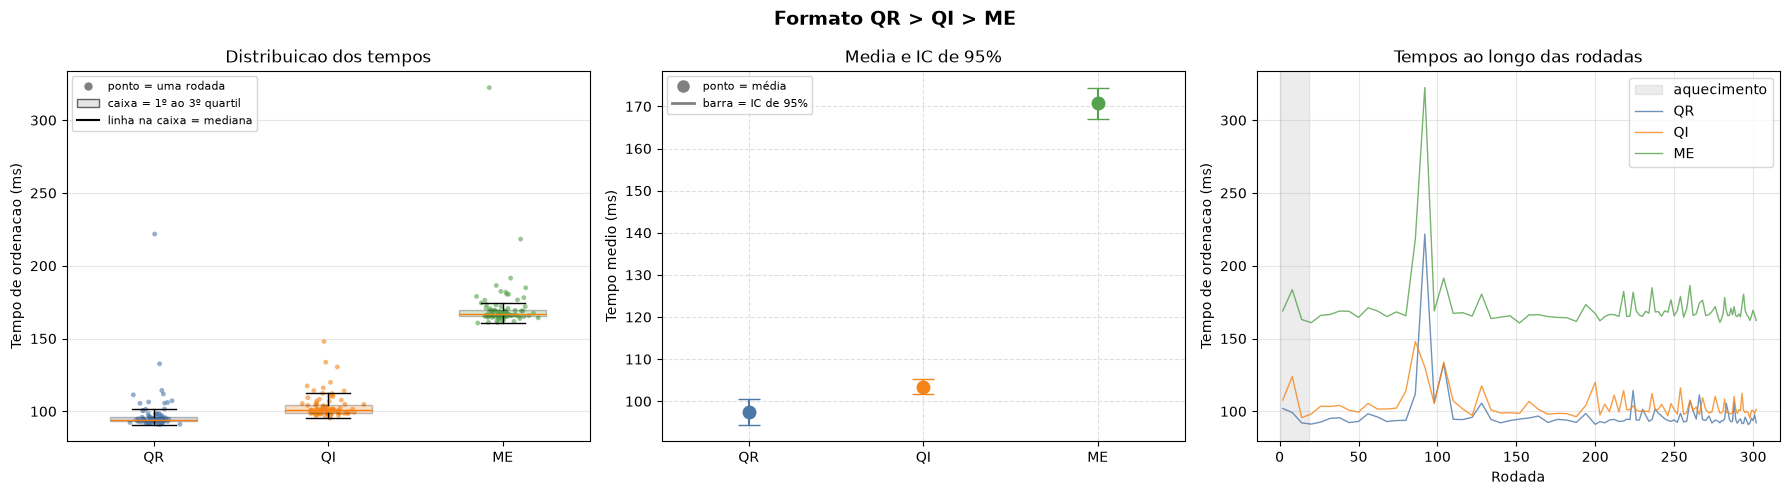

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,91,97.4747,14.5135,94.4521,100.4973,0.0310
1,Quick Sort Iterativo,91,103.4915,8.1297,101.7984,105.1846,0.0164
2,Merge Sort,91,170.7395,17.8522,167.0216,174.4574,0.0218


In [8]:
grafico_formato("QR-ME-QI")

### 2.3 Formato QI > QR > ME

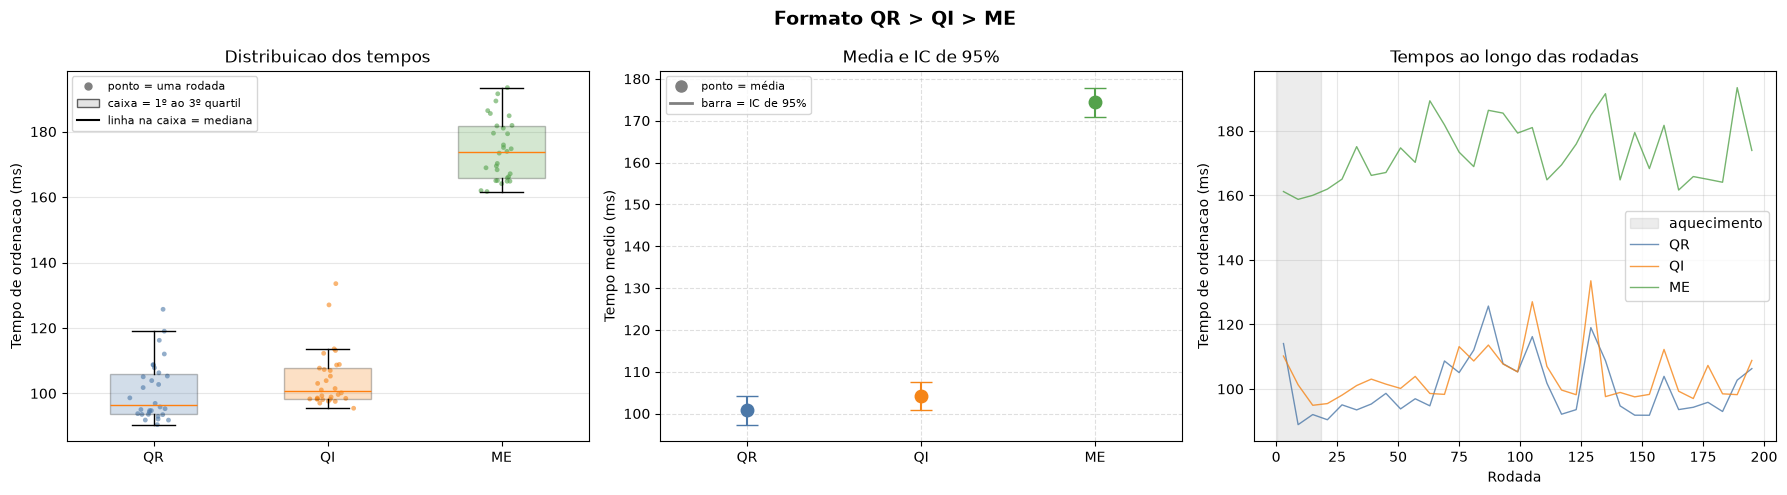

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,30,100.7584,9.1082,97.3573,104.1594,0.0338
1,Quick Sort Iterativo,30,104.2560,8.8156,100.9642,107.5478,0.0316
2,Merge Sort,30,174.3945,9.3750,170.8938,177.8951,0.0201


In [9]:
grafico_formato("QI-QR-ME")

### 2.4 Formato QI > ME > QR

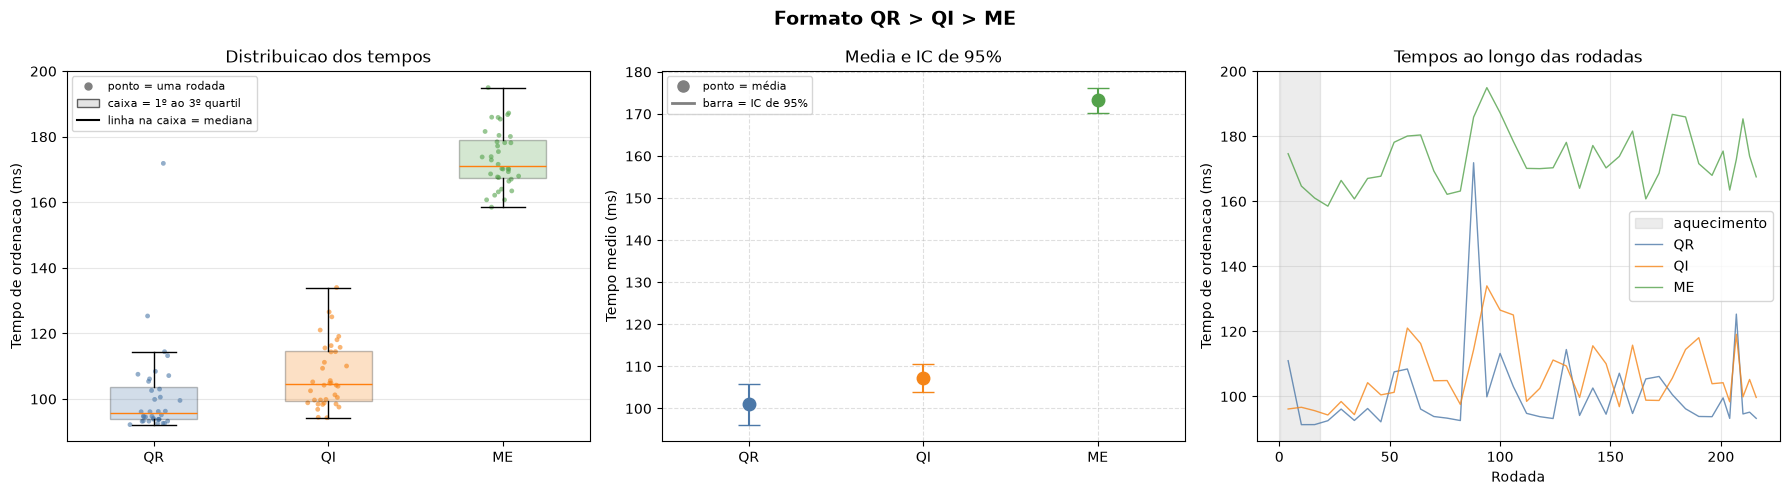

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,36,101.0113,14.3509,96.1557,105.8670,0.0481
1,Quick Sort Iterativo,36,107.3243,9.9136,103.9701,110.6786,0.0313
2,Merge Sort,36,173.2428,8.8937,170.2336,176.2520,0.0174


In [10]:
grafico_formato("QI-ME-QR")

### 2.5 Formato ME > QR > QI

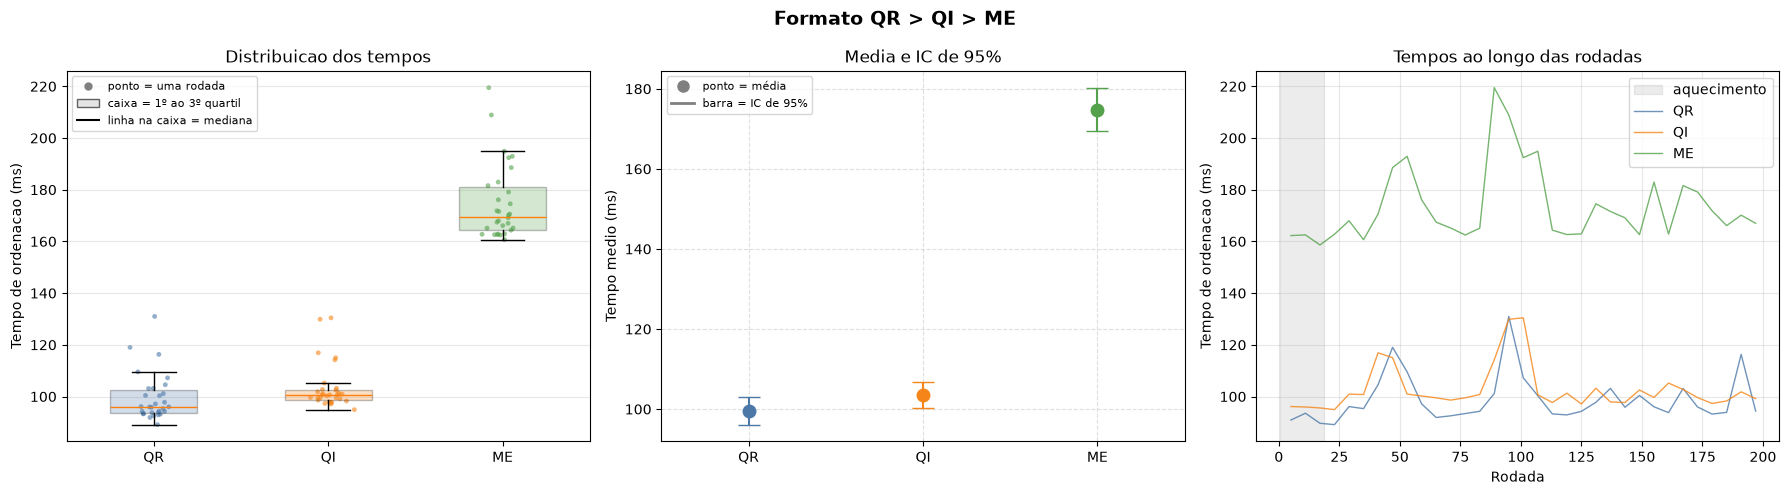

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,30,99.5615,9.2210,96.1183,103.0047,0.0346
1,Quick Sort Iterativo,30,103.4819,8.8879,100.1631,106.8007,0.0321
2,Merge Sort,30,174.8284,14.6487,169.3585,180.2983,0.0313


In [11]:
grafico_formato("ME-QR-QI")

### 2.6 Formato ME > QI > QR

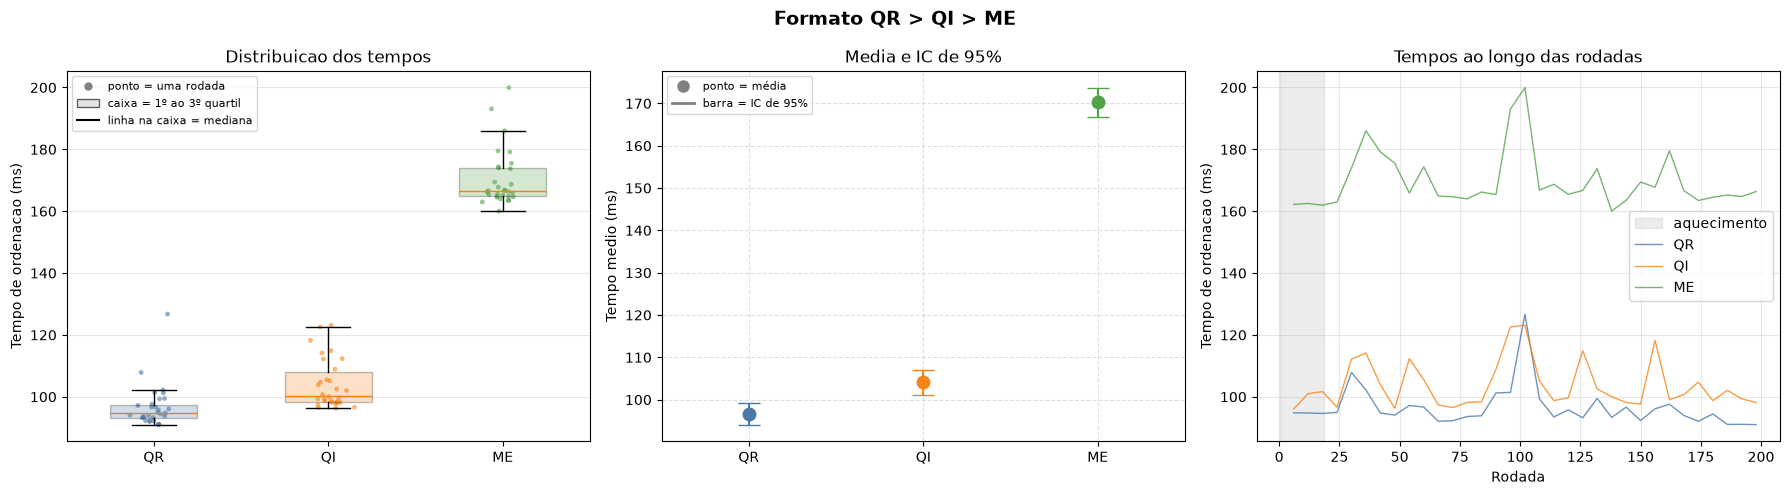

,,n,media (ms),desvio (ms),IC 95% inf (ms),IC 95% sup (ms),erro relativo
0,Quick Sort Recursivo,30,96.6606,6.8791,94.0919,99.2293,0.0266
1,Quick Sort Iterativo,30,104.1315,7.9688,101.1559,107.1071,0.0286
2,Merge Sort,30,170.2872,9.2215,166.8439,173.7306,0.0202


In [12]:
grafico_formato("ME-QI-QR")